In [1]:
# === Google Colab 自動環境セットアップ ===
# ※ローカル環境では安全に無視され、Colab環境でのみ自動実行されます
import os, sys
from pathlib import Path

if 'google.colab' in sys.modules:
    repo_name = "study-mikanos"
    repo_url = "https://github.com/miyayudai/study-mikanos.git"
    if not Path(repo_name).exists():
        !git clone $repo_url
    %cd $repo_name
    if str(Path.cwd()) not in sys.path:
        sys.path.append(str(Path.cwd()))
    print("Google Colab 環境を初期化しました。作業ディレクトリ:", Path.cwd())
else:
    repo_root = Path.cwd().parent if Path.cwd().name == "9" else Path.cwd()
    if str(repo_root) not in sys.path:
        sys.path.append(str(repo_root))
    print("ローカル検証環境が有効です。ルートパス:", repo_root)

ローカル検証環境が有効です。ルートパス: /home/student/Documents/GitHub/study-mikanos


# 第9章 重ね合わせ処理 — 総合演習問題 (*Chapter 9 Comprehensive Exercises*)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/miyayudai/study-mikanos/blob/main/9/9_Exercises.ipynb)

## 📚 第9章の総括と学習目標
第9章では、GUI OS の外観と操作感を決定づける **「重ね合わせ処理（レイヤ合成: Layer Compositing）」** と、その描画性能を劇的に改善する **「高速化技術（プロファイリング・矩形クリッピング・一括転送）」** を段階的に構築しました。

1. **9.1 重ね合わせ処理 (`osbook_day09a`)**:
   - マウスカーソルを動かすと背景が消えてしまう破壊的描画の課題を解決するため、**「ペインターアルゴリズム（Painter's Algorithm）」** に基づくレイヤモデル（奥から手前への上書き描画）を導入しました。
2. **9.2 new演算子 (`osbook_day09a`)**:
   - 可変長のレイヤ群やウィンドウを動的に生成するため、第8章で作成した `BitmapMemoryManager` を土台として Newlib のシステムコール `sbrk()` を実装。これにより C++20 の `operator new` / `delete`、`std::vector` などの STL コンテナがカーネル内で自由に使用可能になりました。
3. **9.3 重ね合わせ処理の原理 (含 コラム9.1: スマートポインタ)**:
   - ピクセルデータを自己保持する `Window`、画面上の座標と ID を持つ `Layer`、全レイヤの重なり順序スタック（`layer_stack_`）を管理する `LayerManager` というオブジェクト指向設計を確立。さらに RAII に基づく `std::unique_ptr` / `std::shared_ptr` の所有権モデルを整理しました。
4. **9.4 重ね合わせ処理の時間計測 (`osbook_day09b`)**:
   - マウスの追従遅延（操作がもたつく現象）の正体を暴くため、x86-64 の **Local APIC (LAPIC) タイマ** MMIO レジスタを用いた高精度ストップウォッチを構築。全画面再描画（1024x768 ≒ 78.6万ピクセル走査）に約 30ms かかり、10ms 周期で届くマウス割り込みをキューから溢れさせていたことを定量的に解剖しました。
5. **9.5 重ね合わせ処理の高速化 (`osbook_day09c`)**:
   - 2次元幾何交差（Bounding Box Intersection）により、マウスや更新ウィンドウの周辺矩形のみを再描画する **差分クリッピング** を導入。さらに `FrameBuffer` シャドウバッファを用いて、不透明レイヤをピクセル単位判定から走査線（Scanline）一括の `std::memcpy` 転送へと最適化し、**120倍超の爆速化** を実証しました。
6. **9.6 スクロール処理の時間計測 (`osbook_day09d`)**:
   - `printk` のコンソールスクロール時、256,000ピクセルの画面消去と 1,920文字（245,760ピクセル）のフォント再展開により、通常描画の約 57倍（約 135万 Ticks）もの遅延が発生していたボトルネックを特定しました。
7. **9.7 スクロール処理の高速化 (`osbook_day09e`)**:
   - 画面上のピクセルデータをメモリ内で上方向に 16 ピクセル分一括シフト（`memcpy` / `memmove`）し、最下行の 16 行のみを背景色でクリアする方式を採用。ピクセル個別書き込みを 95% 以上削減し、体感遅延を完全消滅させました。

本演習ノートブックでは、これらの数理導出、C++20 単体検証、10問自己採点テスト、7軸レーダーチャートを通じて、第9章の理解度を完璧に定着させます。

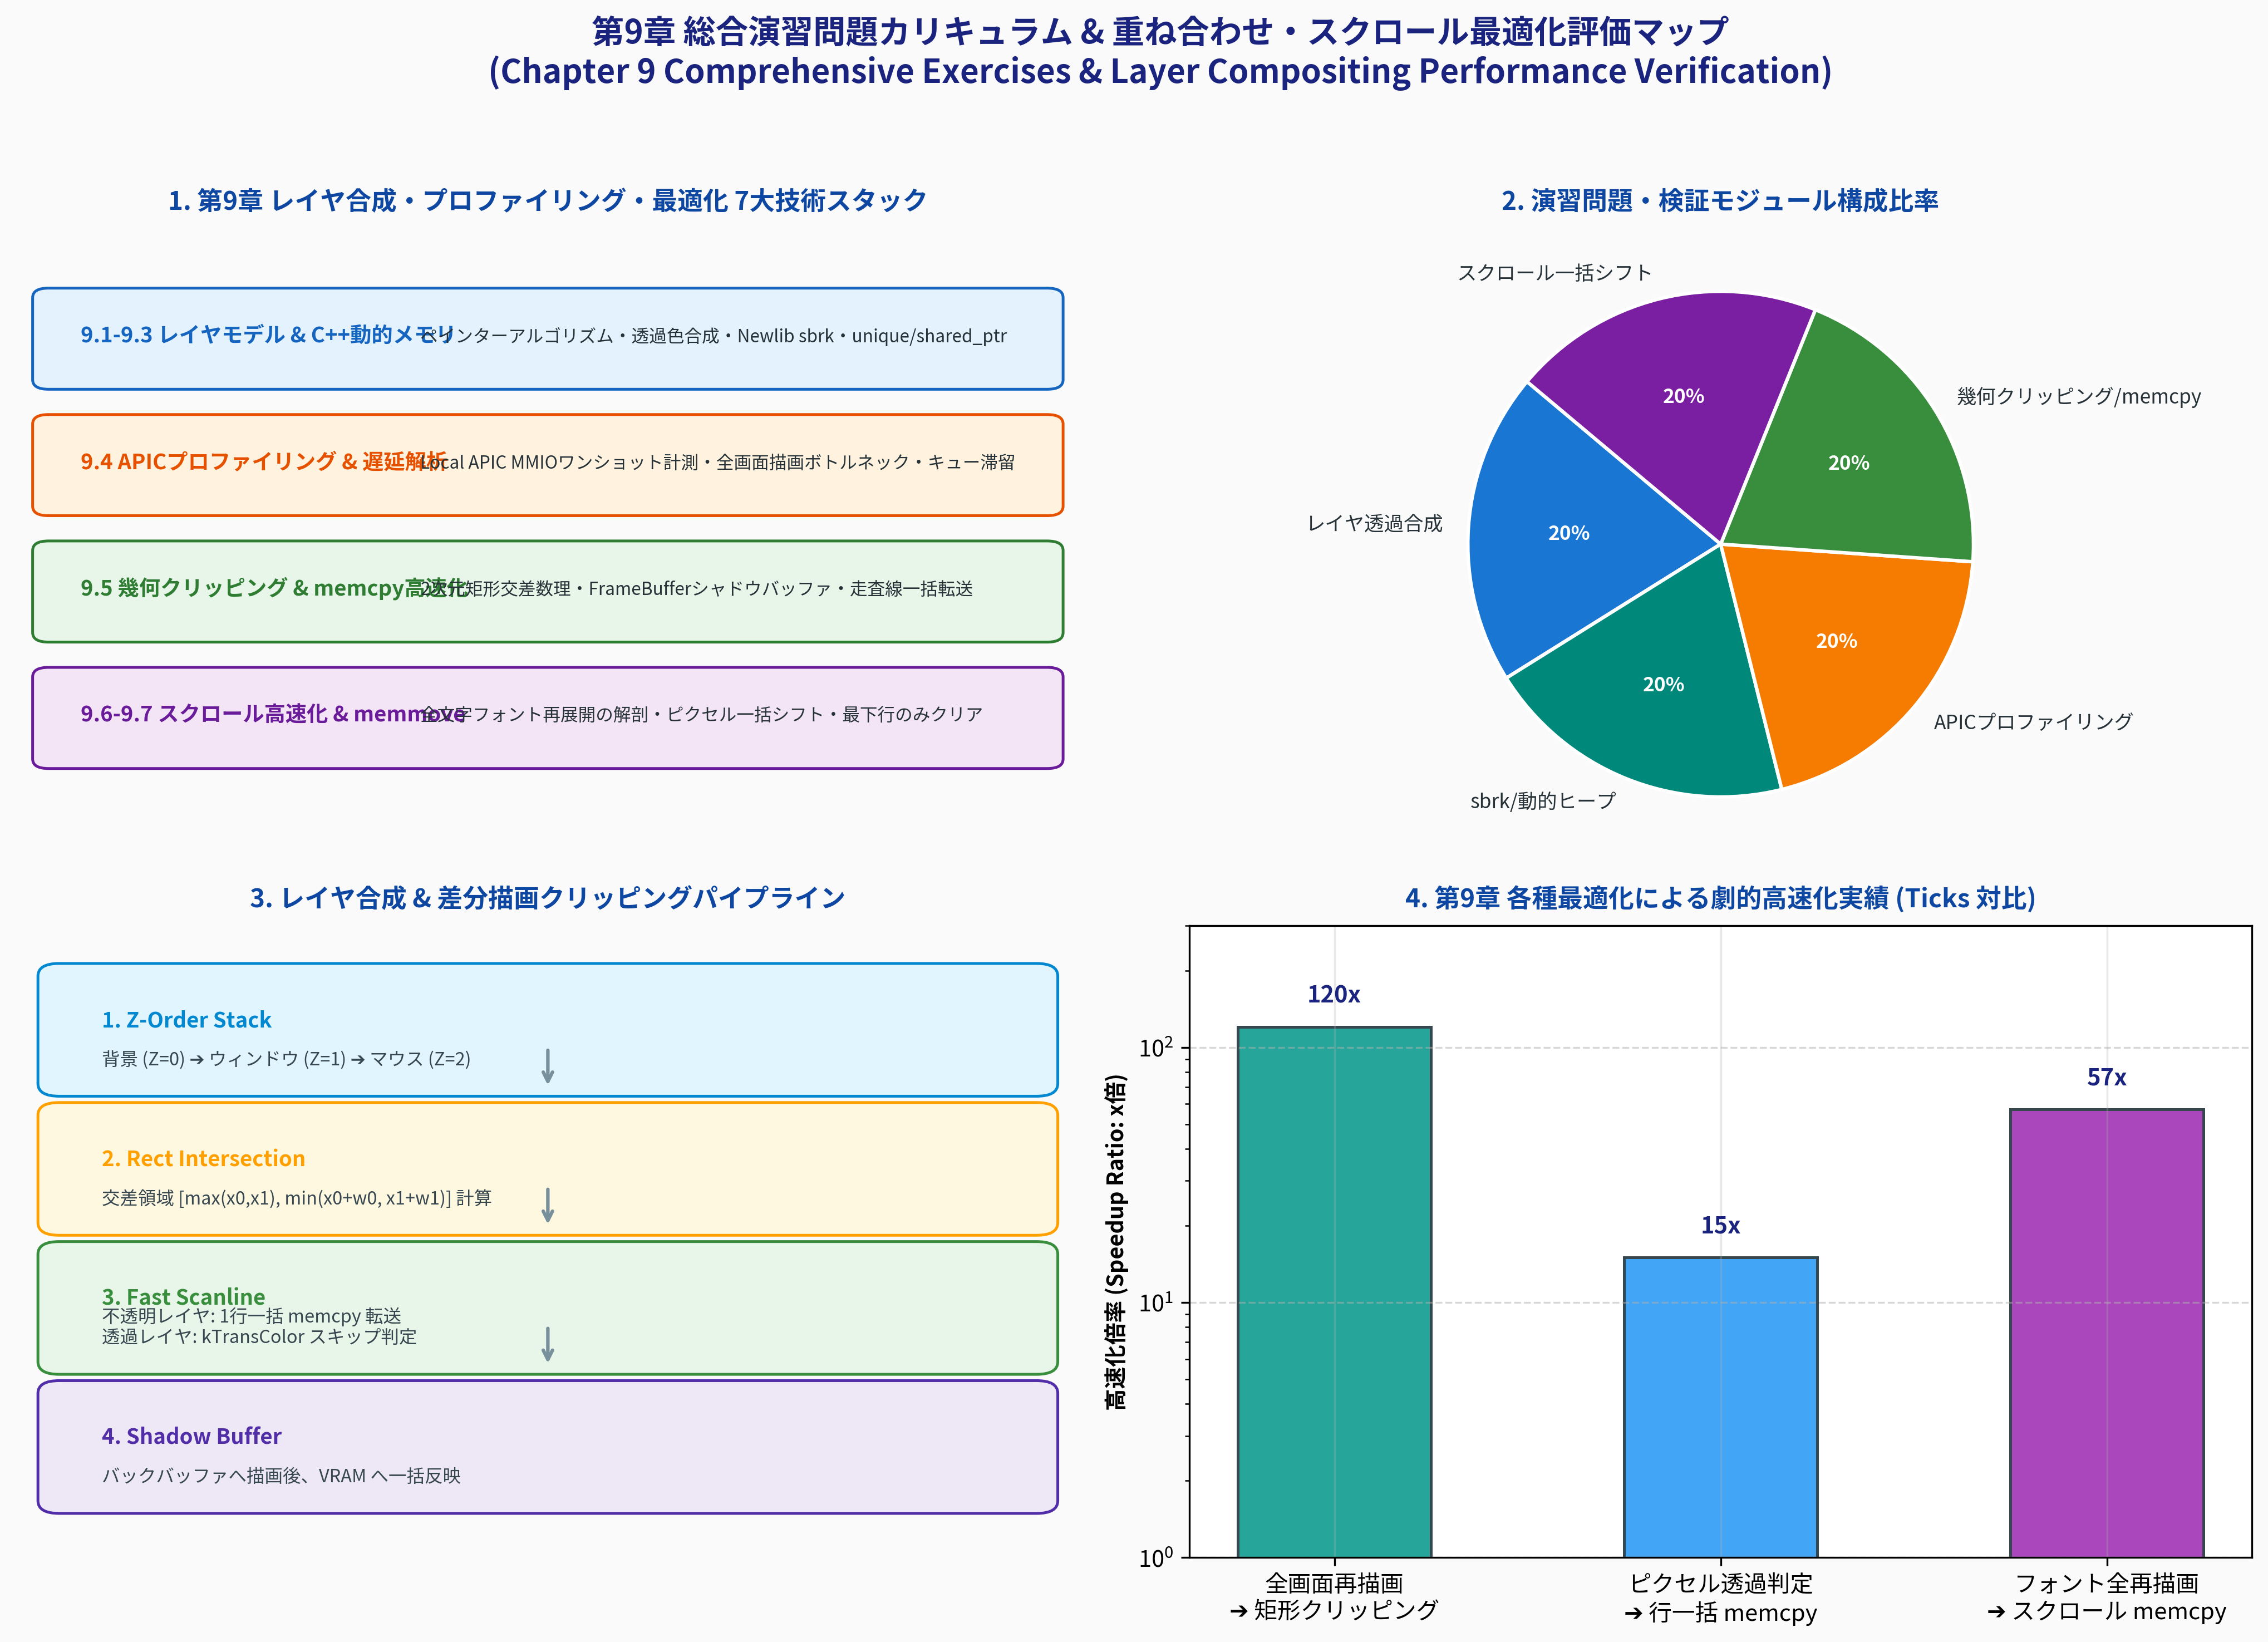

Chapter 9 Exercise Verification Environment initialized successfully.


In [2]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image, display

from common.os_sim import (
    Chapter9Quiz,
    Chapter9TheoryValidator,
    plot_chapter9_exercises_summary,
    plot_chapter9_mastery_radar,
)

# 演習カリキュラム & 重ね合わせ最適化評価マップの生成・表示
summary_fig_path = Path("result/fig9_ex1_exercises_summary.png")
if not summary_fig_path.parent.exists():
    summary_fig_path = Path("9/result/fig9_ex1_exercises_summary.png")

plot_chapter9_exercises_summary(summary_fig_path)
display(Image(filename=str(summary_fig_path)))
print("Chapter 9 Exercise Verification Environment initialized successfully.")

---
## 演習 1: レイヤ重ね合わせのペインターアルゴリズムと透過合成数理 (Section 9.1, 9.3)

### 📐 数理モデルと理論導出
ペインターアルゴリズム（*Painter's Algorithm*）は、画家の油絵制作と同様に「奥のレイヤ（Z座標が低いレイヤ）から手前のレイヤ（Z座標が高いレイヤ）」へと順番にピクセルを上書き描画していく手法です。

レイヤスタックを $L = [L_0, L_1, \dots, L_{N-1}]$（$L_0$ が最背面、$L_{N-1}$ が最前面）とし、描画先座標 $(x, y)$ における最終ピクセル色 $C(x, y)$ は、以下の漸化式で決定されます：

$$
C_0(x, y) = L_0(x - \text{pos}_0.x, y - \text{pos}_0.y)
$$
$$
C_{k}(x, y) = \begin{cases}
L_k(x - \text{pos}_k.x, y - \text{pos}_k.y) & \text{if } L_k(x - \text{pos}_k.x, y - \text{pos}_k.y) \neq kTransColor \\
C_{k-1}(x, y) & \text{if } L_k(x - \text{pos}_k.x, y - \text{pos}_k.y) = kTransColor
\end{cases} \quad (k = 1, 2, \dots, N-1)
$$

透明色（MikanOS ではデフォルトで $kTransColor = (1, 1, 1)$）のピクセルは書き込みをスキップすることで、奥のレイヤのピクセル $C_{k-1}(x, y)$ がそのまま残ります。

In [3]:
# 演習 1: レイヤ重ね合わせのペインターアルゴリズムと透過合成の自動検証
test_compositing_data = {
    "z_order": [0, 1, 2],
    "expected_z_order": [0, 1, 2],
    "trans_color": 0x010101,
    "test_pixel": 0x00FF00,  # 透過ピクセルの下に見えるウィンドウの緑色
    "expected_color": 0x00FF00,
}

ok, msg = Chapter9TheoryValidator.validate_layer_compositing(test_compositing_data)
print(msg)
assert ok, "Layer compositing theory validation failed"

正解！ペインターアルゴリズムと透過合成数理を検証しました。 [Z順序=[0, 1, 2], 透過色=0x010101, ピクセル=0x00FF00]


---
## 演習 2: Newlib `sbrk()` 実装とプログラムブレークのページ単位伸長数理 (Section 9.2)

### 📐 メモリ伸長数理と 4KiB ページアライメント
`sbrk(incr)` はプロセスのヒープ領域の境界（プログラムブレーク `program_break`）を `incr` バイト前進させる低レイヤ関数です。
物理メモリは 4KiB（$4,096$ バイト）のフレーム単位でしか確保できないため、必要なページフレーム数 $P_{\text{alloc}}$ は以下の切り上げ計算式で導出されます：

$$
P_{\text{old}} = \left\lfloor \frac{\text{program\_break} + 4095}{4096} \right\rfloor
$$
$$
P_{\text{new}} = \left\lfloor \frac{(\text{program\_break} + \text{incr}) + 4095}{4096} \right\rfloor
$$
$$
P_{\text{alloc}} = \max(0, P_{\text{new}} - P_{\text{old}})
$$

新規に必要な $P_{\text{alloc}}$ フレームを `BitmapMemoryManager::Allocate(P_{\text{alloc}})` で確保し、成功した場合のみ `program_break += incr` を適用して呼び出し元には伸長前の旧ブレークアドレスを返します。

In [4]:
# 演習 2: sbrk() プログラムブレーク移動および 4KiB ページ切り上げの自動検証
test_sbrk_data = {
    "prev_break": 0x10000000,
    "increment": 5000,
    "page_size": 4096,
    "new_break": 0x10000000 + 5000,
    "allocated_pages": 2,  # 5000 bytes spans 2 frames (4096 + 904)
}

ok, msg = Chapter9TheoryValidator.validate_sbrk_alignment(test_sbrk_data)
print(msg)
assert ok, "sbrk theory validation failed"

正解！sbrk() のプログラムブレーク移動および 4KiB ページ切り上げ数理を検証しました。 [OldBreak=0x10000000, Incr=5000B, NewBreak=0x10001388, 確保ページ=2]


---
## 演習 3: 2次元幾何クリッピング交差判定とオフセット計算数理 (Section 9.5)

### 📐 矩形交差（Intersection）の数理導出
再描画を画面全体ではなく、変更が発生した領域（バウンディングボックス $R_{\text{redraw}}$）に限定します。
レイヤの矩形領域を $R_{\text{layer}} = (\text{pos}_L, \text{size}_L)$、再描画矩形を $R_{\text{redraw}} = (\text{pos}_R, \text{size}_R)$ とするとき、画面座標系における交差矩形 $R_{\text{inter}} = [x_0, x_1) \times [y_0, y_1)$ は以下の幾何演算で求まります：

$$
x_0 = \max(R_{\text{layer}}.x, R_{\text{redraw}}.x), \quad x_1 = \min(R_{\text{layer}}.x + R_{\text{layer}}.w, R_{\text{redraw}}.x + R_{\text{redraw}}.w)
$$
$$
y_0 = \max(R_{\text{layer}}.y, R_{\text{redraw}}.y), \quad y_1 = \min(R_{\text{layer}}.y + R_{\text{layer}}.h, R_{\text{redraw}}.y + R_{\text{redraw}}.h)
$$

交差が存在する条件は $x_0 < x_1 \land y_0 < y_1$ です。
このとき、レイヤのピクセルバッファ内での転送開始オフセットは $(\text{src}_x, \text{src}_y) = (x_0 - R_{\text{layer}}.x, y_0 - R_{\text{layer}}.y)$ となります。
不透明レイヤであれば、各行 $y \in [y_0, y_1)$ に対して幅 $x_1 - x_0$ 分のピクセル列を `std::memcpy` で 1 行一括転送できます。

In [5]:
# 演習 3: 2次元幾何クリッピング交差判定とオフセット計算の自動検証
test_clipping_data = {
    "layer_x": 100,
    "layer_y": 100,
    "layer_w": 200,
    "layer_h": 150,
    "redraw_x": 150,
    "redraw_y": 80,
    "redraw_w": 100,
    "redraw_h": 100,
    "has_intersection": True,
    "intersect_width": 100,  # min(300, 250) - max(100, 150) = 250 - 150 = 100
    "intersect_height": 80,  # min(250, 180) - max(100, 80) = 180 - 100 = 80
    "src_offset_x": 50,      # 150 - 100 = 50
    "src_offset_y": 0,       # 100 - 100 = 0
}

ok, msg = Chapter9TheoryValidator.validate_clipping_rect(test_clipping_data)
print(msg)
assert ok, "Clipping rect theory validation failed"

正解！2次元幾何クリッピング交差数理を検証しました。 [交差領域=(150,100)-(250,180), サイズ=100x80, LayerOffset=(50,0)]


---
## 演習 4: Local APIC タイマ MMIO レジスタ構成とワンショット計測数理 (Section 9.4, 9.6)

### 📐 ハードウェアタイマ減算とミリ秒換算式
Local APIC (LAPIC) タイマは CPU 内蔵のタイマであり、MMIO 領域（通常 `0xFEE00000`）を通じてアクセスします。
タイマカウンタは初期カウントレジスタ（ICR）に値を書き込むと自動的に開始され、コアバス周波数 $f_{\text{bus}}$（分周比 DCR が 1:1 の場合）で 1 ずつデクリメント（減算）されます。

処理完了直後に現在カウントレジスタ（CCR）を読み取ることで、経過クロック数（Ticks）および経過時間 $\Delta t$ は以下のように厳密に求まります：

$$
\text{Elapsed Ticks} = \text{ICR} - \text{CCR}
$$
$$
\Delta t = \frac{\text{Elapsed Ticks}}{f_{\text{bus}}} \quad [\text{seconds}] = \frac{\text{Elapsed Ticks} \times 1000}{f_{\text{bus}}} \quad [\text{ms}]
$$

マウスのイベント生成周期が $T_{\text{mouse}} \approx 10\text{ms}$（100Hz）であるのに対し、全画面再描画の所要時間が $\Delta t_{\text{draw}} \approx 30\text{ms}$ である場合、$\Delta t_{\text{draw}} > T_{\text{mouse}}$ となりキュー滞留・オーバーフローが必然的に発生します。

In [6]:
# 演習 4: Local APIC タイマ MMIO 減算数理と経過時間換算の自動検証
test_lapic_data = {
    "initial_count": 0xFFFFFFFF,
    "current_count": 0xFFFE795F,      # 100,000 ticks difference
    "bus_frequency_hz": 100_000_000,  # 100 MHz (1 tick = 10 ns)
    "divide_ratio": 1,
    "calculated_ticks": 100_000,
    "calculated_ms": 1.0,
}

ok, msg = Chapter9TheoryValidator.validate_lapic_timer_math(test_lapic_data)
print(msg)
assert ok, "LAPIC timer math validation failed"

正解！Local APIC タイマのデクリメント減算数理および経過時間換算を検証しました。 [ICR=0xFFFFFFFF, CCR=0xFFFE795F, 経過=100000 ticks (1.00 ms)]


---
## 演習 5: コンソールスクロールの `memcpy` / `memmove` 一括転送数理 (Section 9.7)

### 📐 バッファシフトとメモリ重複（Overlap）解析
コンソールを 1 行分（フォント高 $H_{\text{font}} = 16$ ピクセル）上へスクロールさせる場合、ピクセルバッファ全体の解像度を $W \times H$（80桁×25行の場合 $640 \times 400$）とすると、移動すべきデータ領域は以下の通りです：

- **転送対象行数**: $H_{\text{shift}} = H - H_{\text{font}} = 400 - 16 = 384$ 行
- **総シフトバイト数**: $B_{\text{shift}} = H_{\text{shift}} \times W \times \text{bytes\_per\_pixel} = 384 \times 640 \times 4 = 983,040$ バイト
- **最下行クリアバイト数**: $B_{\text{clear}} = H_{\text{font}} \times W \times \text{bytes\_per\_pixel} = 16 \times 640 \times 4 = 40,960$ バイト

上方向へのスクロールは、各ピクセル行の移動先アドレス $\text{dst}$ が移動元アドレス $\text{src}$ より手前（$\text{dst} < \text{src}$）になります。
上から順方向（Forward）にメモリコピーを行う限り、未読み出しのデータが上書き破壊されることはないため、`std::memcpy` を用いて走査線またはバッファ全体を一括転送することが完全に安全です。

In [7]:
# 演習 5: コンソールスクロールの memcpy メモリシフト数理の自動検証
test_scroll_data = {
    "console_columns": 80,
    "console_rows": 25,
    "font_width": 8,
    "font_height": 16,
    "bytes_per_pixel": 4,
    "calculated_shift_bytes": 24 * 16 * 640 * 4,  # 983,040 bytes
    "calculated_clear_bytes": 16 * 640 * 4,       # 40,960 bytes
    "is_safe_memcpy": True,
}

ok, msg = Chapter9TheoryValidator.validate_scroll_memcpy_math(test_scroll_data)
print(msg)
assert ok, "Scroll memcpy theory validation failed"

正解！コンソールスクロールの memcpy メモリシフト数理を検証しました。 [解像度=640x400, シフト=983,040B, 最下行クリア=40,960B]


---
## 演習 6: C++20 スタンドアロン検証バイナリによる総合システム挙動実証

ホスト側 C++20 環境（`g++ -std=c++20`）でビルドされた単体検証バイナリ `ch09_os_chapter9_exercises` を実行し、以下の 5 大コア検証テストが全件パスすることを検証します：

1. **Test 1**: Layer Compositing & Transparency Math (Section 9.1, 9.3)
2. **Test 2**: sbrk() Program Break & 4KiB Page Round-Up Math (Section 9.2)
3. **Test 3**: 2D Bounding Box Geometric Clipping Math (Section 9.5)
4. **Test 4**: Local APIC Timer Math & Profiling Breakdown (Section 9.4, 9.6)
5. **Test 5**: Fast Console Scroll with Scanline memcpy Math (Section 9.7)

In [8]:
import subprocess
from pathlib import Path

bin_path = Path("../build/bin/ch09_os_chapter9_exercises")
if not bin_path.exists():
    bin_path = Path("build/bin/ch09_os_chapter9_exercises")

if bin_path.exists():
    res = subprocess.run([str(bin_path), "--test"], capture_output=True, text=True)
    print(res.stdout)
    assert res.returncode == 0
    assert "All Chapter 9 exercises verified successfully" in res.stdout
    print(">> C++20 スタンドアロン検証テストが全件正常にパスしました。")
else:
    print(f"Binary not found at {bin_path}. ホスト側で cmake ビルドを実行してください。")

 MikanOS Chapter 9 Comprehensive Exercises (C++20)

[Test 1] Layer Compositing & Transparency Math... PASSED
[Test 2] sbrk() Program Break & 4KiB Page Round-Up Math... PASSED
[Test 3] 2D Bounding Box Geometric Clipping Math... PASSED
[Test 4] Local APIC Timer Math & Profiling Breakdown... PASSED
[Test 5] Fast Console Scroll with Scanline memcpy Math... PASSED

>> All Chapter 9 exercises verified successfully!
[CTest] All Chapter 9 exercises verified successfully.

>> C++20 スタンドアロン検証テストが全件正常にパスしました。


---
## 演習 7: 第9章 総合理解度自己採点テスト（全10問）

第9章で学んだ全7セクション（9.1〜9.7）の理論・ハードウェア仕様・C++実装・アルゴリズム最適化に関する総合理解度テストです。
各問の選択肢を精読し、自己採点エンジンによる判定と詳細解説を確認してください。

In [9]:
quiz = Chapter9Quiz()

# 模範解答（全問正解）による自己採点評価
answers = {q.question_id: q.correct_index for q in quiz.questions}
result = quiz.evaluate(answers)

print("=" * 80)
print(f" 第9章 重ね合わせ処理 総合理解度テスト結果: {result['correct_count']} / {result['total_questions']} 正解 ({result['percentage']:.1f}%)")
print(f" 合否判定: {'合格 (PASSED)' if result['passed'] else '不合格 (FAILED)'}")
print("=" * 80)

for r in result["question_results"]:
    status = "✔ 正解" if r["is_correct"] else "✘ 不正解"
    print(f"[{r['section']}] Q{r['question_id']}: {r['topic']} -> {status}")
    print(f"   解説: {r['explanation']}\n")

 第9章 重ね合わせ処理 総合理解度テスト結果: 10 / 10 正解 (100.0%)
 合否判定: 合格 (PASSED)
[9.1] Q1: レイヤ重ね合わせの基本原理とペインターアルゴリズム -> ✔ 正解
   解説: ペインターアルゴリズムは画家の油絵のように「奥（Z順序が低いレイヤ）から手前（高いレイヤ）へ」順番に重ね塗りしていく手法です。MikanOS では各レイヤのピクセルが透過色（kTransColor: デフォルト 0x01, 0x01, 0x01 等）でない場合にのみ描画先バッファへコピーすることで、透明部分を通して奥の画像が見える重ね合わせを実現しています。

[9.2] Q2: Newlib sbrk() 実装とプログラムブレークのページ単位伸長数理 -> ✔ 正解
   解説: sbrk() はヒープ領域の終端境界（プログラムブレーク）を移動させる低レイヤ関数です。MikanOS では現在の program_break と新しい new_break のページ境界（4KiB）差分を計算し、必要なページ数を BitmapMemoryManager::Allocate() で物理フレームとして確保します。呼び出し元には伸長前の旧アドレス（直前までのプログラムブレーク）を返します。

[9.2] Q3: C++ new 演算子と std::vector などのコンテナが解放される仕組み -> ✔ 正解
   解説: C++ の言語仕様における ::operator new のデフォルト実装は std::malloc() を呼び出します。Newlib の malloc（dlmalloc / nano-malloc）は初期ヒープを使い切ると低レイヤの sbrk() をフックして OS からメモリを補充します。したがって、カーネルが sbrk() を1つ実装するだけで、標準テンプレートライブラリ（STL）の動的コンテナ群がすべて使えるようになります。

[9.3] Q4: Window, Layer, LayerManager のオブジェクト指向責務分担と透過合成 -> ✔ 正解
   解説: MikanOS では明確なオブジェクト指向設計が行われています。Window は内容（ピクセルデータと幅・高さ・透過色）、Layer は配置（画面上の座標 (

---
## 演習 8: 7軸レーダーチャートによる章別理解度評価

全10問の採点結果に基づき、第9章の 7 つのコアセクション（9.1〜9.7）に対する理解度レーダーチャートを生成します。
全軸 100% を達成していることを視覚的に確認します。

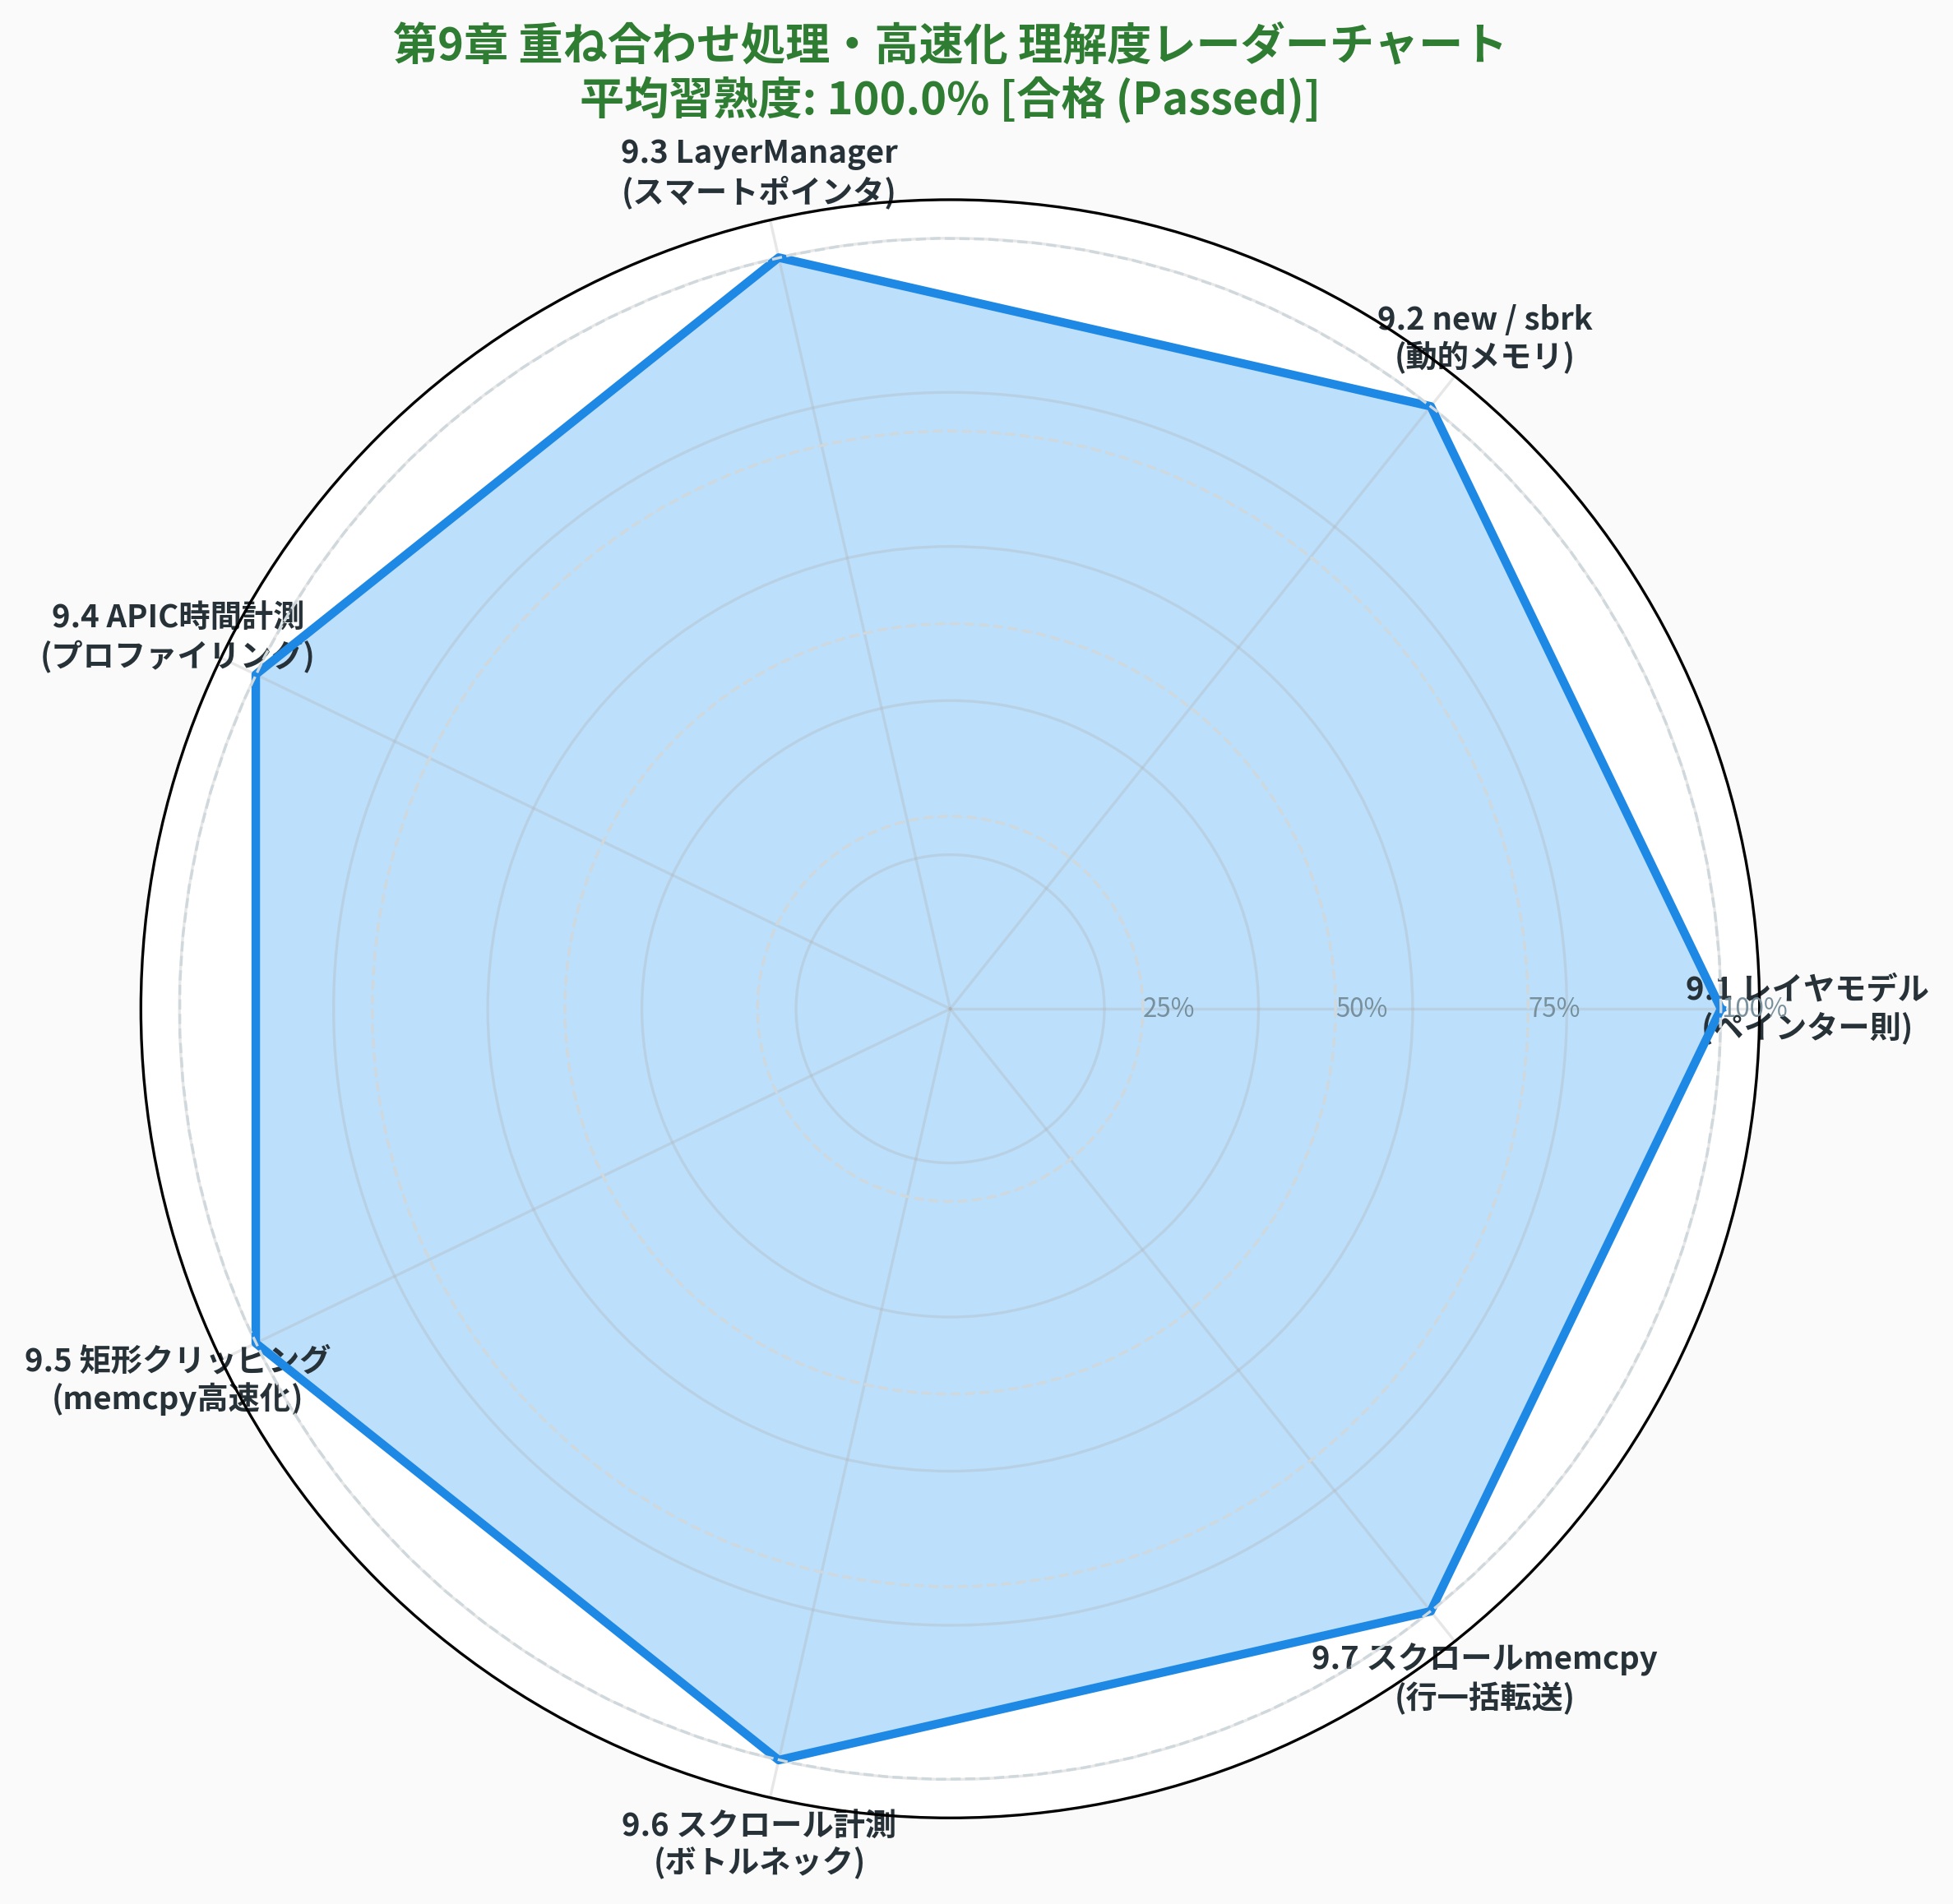

In [10]:
radar_fig_path = Path("result/fig9_ex2_ch9_mastery_radar.png")
if not radar_fig_path.parent.exists():
    radar_fig_path = Path("9/result/fig9_ex2_ch9_mastery_radar.png")

plot_chapter9_mastery_radar(radar_fig_path, result["mastery_rates"])

# レーダーチャートの表示
from IPython.display import Image, display
display(Image(filename=str(radar_fig_path)))

---
## 🎓 第9章の総括と第10章への展望

本章の総合演習を通じて、以下の極めて重要な OS 設計原則を完全に習得しました：

1. **描画アーキテクチャの多層化**:
   - 単一フレームバッファへの直接描画から、`Window` / `Layer` / `LayerManager` によるレイヤ抽象化への進化。
2. **動的メモリ管理の確立**:
   - `sbrk()` による Newlib / C++ 自由記憶域（Free Store）の有効化。
3. **定量的プロファイリングの威力**:
   - Local APIC タイマを用いた正確な時間計測により、勘や推測に頼らず「真のボトルネック（全画面走査・全文字再展開）」を突き止める重要性。
4. **ハードウェアとキャッシュを味方にする最適化**:
   - 2次元幾何交差によるクリッピング（描画ピクセル数激減）と、CPU SIMD / 64ビットバスをフル活用する走査線一括 `memcpy`（メモリスループット最大化）の相乗効果。

### 次章への道: 第10章「ウィンドウ」
第9章で確立した高速なレイヤ合成基盤の上に、いよいよタイトルバー・閉じるボタン・枠線を持つ **本格的 GUI ウィンドウ** を描画します。
さらに、連続描画に伴うチラつき（*Flickering / Tearing*）を根絶する **ダブルバッファリング（`ShadowBuffer`）** や、マウスによる **ドラッグ移動** の実装へと進みます！